# Raport Laboratori

**Lënda:** Hyrje në Elektronikë  
**Tema:** Analiza e Qarqeve, Rezistencave dhe Përdorimi i Breadboard  
**Emri:** Alda Xhika  
**Data e punimit:** 22/11/2026  
**Data e dorëzimit:** 22/11/2026

## 1. Qëllimi i Eksperimentit

Qëllimi i këtij eksperimenti është të studiohet sjellja e qarqeve elektrike të thjeshta në konfigurime të ndryshme (*Burimi*, *Seri* dhe *Paralel*) duke përdorur rezistenca (120 kΩ dhe 1.77 kΩ) dhe *breadboard*. Gjithashtu, synohet matja e rrymës ($I$) dhe tensionit ($V_{in}$, $V_{out}$), llogaritja e amplifikimit, analiza e grafikëve dhe identifikimi i burimeve të gabimeve eksperimentale.

## 2. Baza Teorike

* **Ligji i Ohmit:** Marrëdhënia midis tensionit ($V$), rrymës ($I$) dhe rezistencës ($R$) jepet nga:
  $$V = I \cdot R \quad \Longrightarrow \quad I = \frac{V}{R}$$

* **Lidhja në seri:** Rezistencat e lidhura në seri kanë të njëjtën rrymë që kalon nëpër secilën prej tyre, ndërsa rezistenca ekuivalente është shuma e rezistencave individuale:
  $$R_{eq,\text{seri}} = R_1 + R_2$$

* **Lidhja në paralel:** Rezistencat e lidhura në paralel kanë të njëjtin tension në skajet e tyre, ndërsa rezistenca ekuivalente jepet nga:
  $$R_{eq,\text{paralel}} = \left(\frac{1}{R_1} + \frac{1}{R_2}\right)^{-1} = \frac{R_1 R_2}{R_1 + R_2}$$

* **Amplifikimi i tensionit:** Raporti midis tensionit dalës ($V_{out}$) dhe tensionit hyrës ($V_{in}$) jepet nga:
  $$A_v = \frac{V_{out}}{V_{in}}$$

## 3. Ndërtimi Eksperimental

1. Përgatitja e *breadboard*-it dhe verifikimi i vazhdimësisë së linjave të ushqimit dhe rreshtave të kontaktit.
2. Vendosja dhe lidhja e rezistorëve me vlera 120 kΩ dhe 1.77 kΩ sipas skemës përkatëse të konfigurimit (*Burimi*, *Seri* dhe *Paralel*).
3. Furnizimi i qarkut me tension hyrës $V_{in} = 11.69\text{ V}$ dhe kryerja e matjeve të rrymës ($I$) dhe tensionit dalës ($V_{out}$) me pajisjet matëse laboratorike.
4. Regjistrimi i vlerave të matura në tabelë dhe llogaritja e amplifikimit aty ku aplikohet.

# 4. Te Dhenat e Matura

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 4. Të dhënat e matura
data = {
    "Konfigurimi": ["Burimi", "Seri", "Paralel"],
    "Rezistenca": [
        "120 kΩ dhe 1.77 kΩ",
        "120 kΩ dhe 1.77 kΩ",
        "120 kΩ dhe 1.77 kΩ",
    ],  #[cite: 1]
    "Rryma (A)": [2.263, 0.0, 2.256],  #[cite: 1]
    "Vin (V)": [11.69, 11.69, 11.69],  #[cite: 1]
    "Vout (V)": [np.nan, 3.93, 11.36],  #[cite: 1]
    "Amplifikimi": [np.nan, 0.3361847733105218, 0.9717707442258341],  #[cite: 1]
}

df = pd.DataFrame(data)
display(df)

,Konfigurimi,Rezistenca,Rryma (A),Vin (V),Vout (V),Amplifikimi
0,Burimi,120 kΩ dhe 1.77 kΩ,2.263,11.69,NaN,NaN
1,Seri,120 kΩ dhe 1.77 kΩ,0.000,11.69,3.93,0.336185
2,Paralel,120 kΩ dhe 1.77 kΩ,2.256,11.69,11.36,0.971771


# 5. Analiza e Te Dhenave

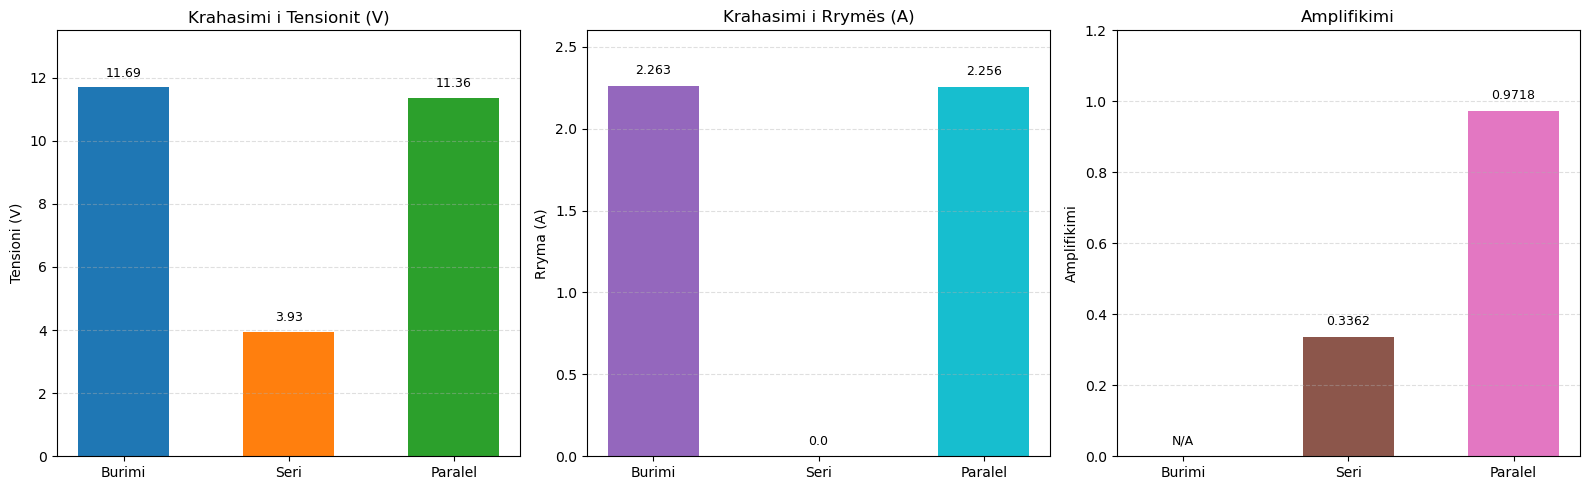

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from matplotlib import MatplotlibDeprecationWarning

warnings.filterwarnings("ignore", category=MatplotlibDeprecationWarning)

# Krijimi i grafikëve
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
konfig = df["Konfigurimi"]

# 1. Krahasimi i Tensionit (V)
tension_vals = df["Vout (V)"].fillna(df["Vin (V)"])

tension_labels = [
    f"{df['Vin (V)'].iloc[0]:.2f}",
    f"{df['Vout (V)'].iloc[1]:.2f}",
    f"{df['Vout (V)'].iloc[2]:.2f}",
]

colors_v = ["#1f77b4", "#ff7f0e", "#2ca02c"]

bars_v = axes[0].bar(
    konfig, tension_vals, width=0.55, color=colors_v
)

axes[0].set_title("Krahasimi i Tensionit (V)")
axes[0].set_ylabel("Tensioni (V)")
axes[0].set_ylim(0, 13.5)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for bar, lbl in zip(bars_v, tension_labels):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.25,
        lbl,
        ha="center",
        va="bottom",
        fontsize=9,
    )

# 2. Krahasimi i Rrymës (A)
colors_i = ["#9467bd", "#d62728", "#17becf"]

bars_i = axes[1].bar(
    konfig, df["Rryma (A)"], width=0.55, color=colors_i
)

axes[1].set_title("Krahasimi i Rrymës (A)")
axes[1].set_ylabel("Rryma (A)")
axes[1].set_ylim(0, 2.6)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars_i:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{bar.get_height():.3f}" if bar.get_height() > 0 else "0.0",
        ha="center",
        va="bottom",
        fontsize=9,
    )

# 3. Amplifikimi sipas Konfigurimit
amp_vals = df["Amplifikimi"].fillna(0)
colors_a = ["#7f7f7f", "#8c564b", "#e377c2"]

bars_a = axes[2].bar(
    konfig, amp_vals, width=0.55, color=colors_a
)

axes[2].set_title("Amplifikimi")
axes[2].set_ylabel("Amplifikimi")
axes[2].set_ylim(0, 1.2)
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

for i, bar in enumerate(bars_a):
    txt = (
        "N/A"
        if pd.isna(df["Amplifikimi"].iloc[i])
        else f"{amp_vals.iloc[i]:.4f}"
    )

    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.025,
        txt,
        ha="center",
        va="bottom",
        fontsize=9,
    )

# Rregullimi dhe ruajtja e grafikëve
plt.tight_layout()

plt.savefig(
    "grafiku i matjeve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Analiza e Gabimeve

* **Gabime sistematike dhe të instrumenteve:** Toleranca e rezistorëve, rezistenca e brendshme e instrumenteve matëse dhe kufijtë e saktësisë së tyre mund të ndikojnë në vlerat e regjistruara të tensionit dhe rrymës.
* **Gabime kontakti në *breadboard*:** Kontaktet jo të qëndrueshme ose rezistenca e kontakteve në *breadboard* mund të shkaktojnë luhatje apo vlera të ulëta/ndryshe nga pritshmëritë (p.sh. vlera `0.0 A` e regjistruar në konfigurimin *Seri*)[cite: 1].
* **Gabime njerëzore dhe leximi:** Rrumbullakimi i vlerave gjatë leximit ose pozicionimi i gabuar i sondave matëse gjatë eksperimentit.

## 7. Diskutimi

* Tensioni hyrës mbeti konstant në $11.69\text{ V}$ në të gjitha rastet.
* Në konfigurimin **Paralel**, tensioni dalës arriti $11.36\text{ V}$ (amplifikim rreth $0.9718$) me rrymë $2.256\text{ A}$, afër vlerës së burimit ($2.263\text{ A}$).
* Në konfigurimin **Seri**, u mat tension dalës $3.93\text{ V}$ (amplifikim rreth $0.3362$) dhe rrymë $0.0\text{ A}$, çka tregon për një qark të hapur, kontakt të lirë në *breadboard* ose limit të rezolucionit të matjes.
* Te **Burimi**, $V_{out}$ shënohet si `N/A` sepse matja i referohet drejtpërdrejt burimit me $V_{in} = 11.69\text{ V}$ dhe rrymë $2.263\text{ A}$.

## 8. Përfundimi

* Eksperimenti tregoi qartë se mënyra e lidhjes së elementeve në *breadboard* (*Burimi*, *Seri*, *Paralel*) ndikon drejtpërdrejt në shpërndarjen e tensionit, rrymës dhe amplifikimit. Përdorimi i *breadboard*-it ofron fleksibilitet për ndërtimin e qarqeve, por kërkon kujdes të madh te cilësia e kontakteve dhe saktësia e matjeve për të shmangur anomali si rryma zero në seri.